In [8]:
import torch
from torch.utils.data import Dataset, DataLoader, TensorDataset

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

import os
import numpy as np
import random
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from torchvision.datasets.utils import download_url

In [9]:
from torchvision.datasets import MovingMNIST
from torch.utils.data import DataLoader, random_split

videos = MovingMNIST(
    root="./data",
    split=None,
    download=True,
)

trainset, testset = random_split(
    videos,
    [9000, 1000],
    generator=torch.Generator().manual_seed(42),
)

trainloader = DataLoader(trainset, batch_size=64, shuffle=True)
testloader = DataLoader(testset, batch_size=64, shuffle=False)

0.0%

100.0%


torch.Size([64, 20, 1, 64, 64])


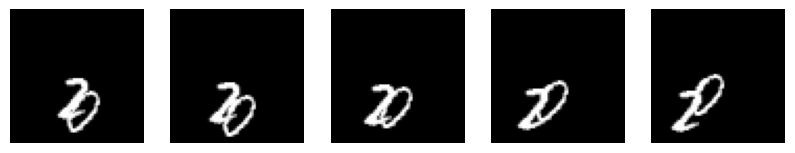

In [13]:
batch_size = 50
#Seeing what the data looks like
batch = next(iter(trainloader))
print(batch.shape) 

fig, axes = plt.subplots(1, 5, figsize=(10, 2))
for t, ax in enumerate(axes):
    ax.imshow(batch[0, t, 0], cmap="gray")
    ax.axis("off")
plt.show()

In [17]:
# we enter input and we output a tensor of size [batch_size, 64]
class Encoder(nn.Module):
    def __init__(self):
        super(Encoder, self).__init__() #just makes it so you can initialize them both implicitly
        self.model = nn.Sequential( 
            nn.Conv2d(1,400, 5, 2, 0), #torch.nn.Conv2d(in_channels, out_channels, kernel_size, stride=1, padding=0, dilation=1, groups=1, bias=True, padding_mode='zeros', device=None, dtype=None)
            nn.LeakyReLU(0.2, inplace=True), #first term is the negative slope, inplace means it deletes the original value of the input and reassigns it to whatever the output (saves a little memory, useful for sequential)
            nn.Conv2d(400,100, 5, 2, 0),
            nn.ReLU(),
            nn.Conv2d(100,80, 3, 1, 0), #to calculate the dimensions of output: [(W−K+2P)/S]+1 where [] is floor and W is choice input dim, S = stride length, K = kernel size,P=padding
            nn.LeakyReLU(0.2, inplace=True), 
            nn.AdaptiveAvgPool2d((2, 2)),
            nn.Flatten(1), #flattens everything - (start_dim=1, end_dim = -1), so here 1 means start flattening at the first dimension
            nn.Linear(320,100), #torch.nn.Linear(in_features, out_features, bias=True, device=None, dtype=None) in and out_features are number of columns of input and output
            nn.ReLU(),
            nn.Linear(100,64),
        )
    def forward(self, input):
        return self.model(input)

In [27]:
#the following code is from the original authors' SIGReg code: https://github.com/galilai-group/lejepa/blob/main/MINIMAL.md?utm_source=chatgpt.com#the-code
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision.transforms import v2

class SIGReg(torch.nn.Module):
    def __init__(self, knots=17):
        super().__init__()
        t = torch.linspace(0, 3, knots, dtype=torch.float32)
        dt = 3 / (knots - 1)
        weights = torch.full((knots,), 2 * dt, dtype=torch.float32)
        weights[[0, -1]] = dt
        window = torch.exp(-t.square() / 2.0)
        self.register_buffer("t", t)
        self.register_buffer("phi", window)
        self.register_buffer("weights", weights * window)

    def forward(self, proj):
        A = torch.randn(proj.size(-1), 256, device=proj.device, dtype = proj.dtype)
        A = A.div_(A.norm(p=2, dim=0))
        x_t = (proj @ A).unsqueeze(-1) * self.t
        err = (x_t.cos().mean(-3) - self.phi).square() + x_t.sin().mean(-3).square()
        statistic = (err @ self.weights) * proj.size(-2)
        return statistic.mean()

In [28]:
device = next(encoder.parameters()).device
sigreg = SIGReg().to(device)

encoder = Encoder()

predictor = nn.Sequential(
    nn.Linear(128, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
)

optimizer = torch.optim.Adam(list(encoder.parameters()) + list(predictor.parameters()), lr=0.0002, betas=(0.5, 0.999)) 
#lr = learning rate, betas = coefs used when calculating averages of gradient etc, net.parameters() are variables to optimize (weights and biases); 
criterion = nn.MSELoss() 
# finds mean squared error
if not os.path.exists('output'):
    os.makedirs('output')

In [ ]:
losses = []
epochs = 7

for epoch in range(epochs):
    j = 0
    for batch in trainloader:
        j += 1
        optimizer.zero_grad()
        
        frames = batch.to(device).float() / 255.0 #making the values [0,1]

            #creating frames to encode: 
        t = torch.randint(frames.shape[1] - 2, ()).item()

        z0 = encoder(frames[:, t])
        z1 = encoder(frames[:, t + 1])
        z2 = encoder(frames[:, t + 2])

            #generating prediction:
        prediction = predictor(torch.cat([z0, z1], dim=1))

            #generating the alignment mse loss and the sigreg loss
        prediction_loss = nn.functional.mse_loss(prediction, z2)
        sigreg_loss = (sigreg(z0) + sigreg(z1) + sigreg(z2)) / 3

        weight = 0.05  # constant that will need tuning, just guessed a value
        loss = prediction_loss + weight * sigreg_loss
        
        optimizer.zero_grad()        # net.zero_grad, loss.backward(), and optimizer.step() are the necessary steps for backpropagation 
                                # (reset gradients, do backpropagation, set new parameters)
        loss.backward()
        optimizer.step()
        
        print('Epoch %d/%d; batch %d/%d; loss %.4f' % (epoch, epochs, j, len(trainloader), loss))
    
    losses.append(loss.item()) #append the loss for each epoch
print(label_probs)

Epoch 0/7; batch 1/141; loss 1.3006
Epoch 0/7; batch 2/141; loss 1.2981
Epoch 0/7; batch 3/141; loss 1.2965
Epoch 0/7; batch 4/141; loss 1.2947
Epoch 0/7; batch 5/141; loss 1.2934
Epoch 0/7; batch 6/141; loss 1.2929
Epoch 0/7; batch 7/141; loss 1.2918
Epoch 0/7; batch 8/141; loss 1.2914
Epoch 0/7; batch 9/141; loss 1.2904
Epoch 0/7; batch 10/141; loss 1.2896
Epoch 0/7; batch 11/141; loss 1.2887
Epoch 0/7; batch 12/141; loss 1.2867
Epoch 0/7; batch 13/141; loss 1.2847
Epoch 0/7; batch 14/141; loss 1.2796
Epoch 0/7; batch 15/141; loss 1.2675
Epoch 0/7; batch 16/141; loss 1.2496
Epoch 0/7; batch 17/141; loss 1.2183
Epoch 0/7; batch 18/141; loss 1.1246
Epoch 0/7; batch 19/141; loss 1.0918
Epoch 0/7; batch 20/141; loss 1.0099
Epoch 0/7; batch 21/141; loss 0.8745
Epoch 0/7; batch 22/141; loss 0.9172
Epoch 0/7; batch 23/141; loss 0.8733
Epoch 0/7; batch 24/141; loss 0.8883
Epoch 0/7; batch 25/141; loss 0.8128
Epoch 0/7; batch 26/141; loss 0.8597
Epoch 0/7; batch 27/141; loss 0.7858
Epoch 0/7;

In [ ]:
# save the weights of the trained network
torch.save(net.state_dict(), 'output/net.pth')

# save the loss values during training
np.save('output/losses', np.array(losses))